تعداد ردیف‌ها: 53,940 | تعداد ستون‌ها: 10
ستون‌ها: ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


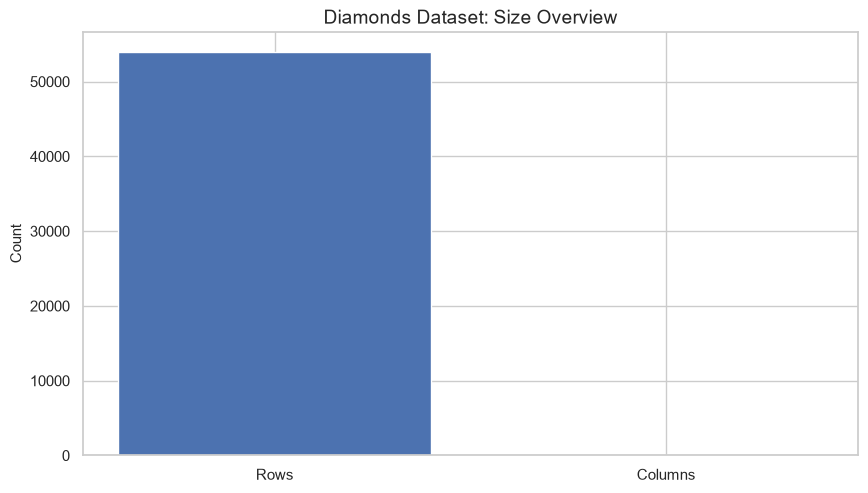

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5.5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

if os.path.exists('diamonds.csv'):
    df = pd.read_csv('diamonds.csv')
else:
    try:
        df = sns.load_dataset('diamonds')
    except Exception:
        url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv'
        df = pd.read_csv(url)

print(f'Number of rows: {len(df):,} | Number of columns: {df.shape[1]}')
print('Columns:', list(df.columns))
display(df.head())

fig, ax = plt.subplots()
ax.bar(['Rows', 'Columns'], [df.shape[0], df.shape[1]])
ax.set_title('Diamonds Dataset: Size Overview')
ax.set_ylabel('Count')
plt.show()

,missing_count
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
price,0
x,0
y,0
z,0


IndexError: index 0 is out of bounds for axis 0 with size 0

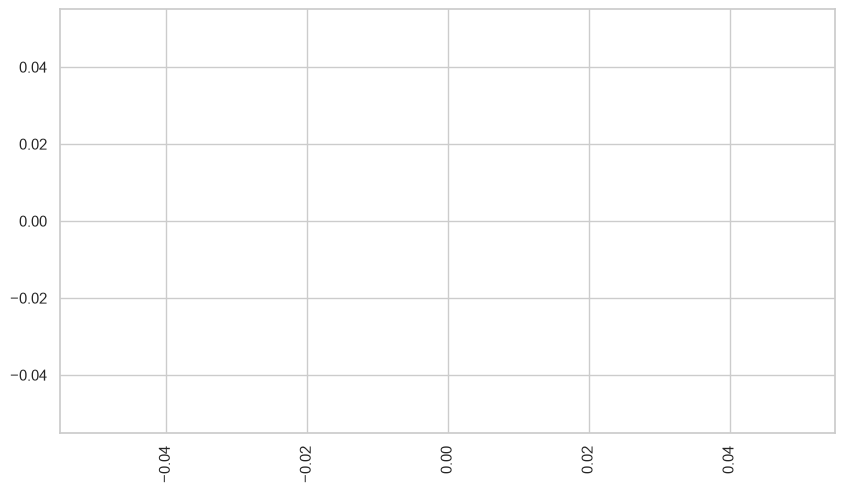

In [2]:
df.columns = df.columns.str.strip().str.lower()
required = {'carat','cut','color','clarity','depth','table','price','x','y','z'}
missing_cols = required - set(df.columns)
if missing_cols:
    raise ValueError(f'{missing_cols}')

missing = df.isna().sum()
duplicates = df.duplicated().sum()
display(missing.to_frame('missing_count'))

fig, ax = plt.subplots()
missing[missing > 0].sort_values(ascending=False).plot(kind='bar', ax=ax)
ax.set_title('Missing Values by Column')
ax.set_xlabel('Column'); ax.set_ylabel('Missing count')
plt.show()